# Build a tiny GPT from scratch

We will train a character-level, decoder-only transformer from random weights. You will implement attention rather than call a pretrained model. PyTorch handles tensor arithmetic, automatic differentiation, and optimization.

**Outcome:** a small Shakespeare-style text generator, a saved model, before/after samples, and measured training and validation losses. Expect imperfect text rather than a conversational assistant.

**Colab:** upload this notebook, select **Runtime → Change runtime type → GPU**, and run cells in order. No other project files are needed. Locally, use a Jupyter kernel with PyTorch installed.

The text comes from [Karpathy's tiny Shakespeare corpus](https://github.com/karpathy/char-rnn/tree/master/data/tinyshakespeare). The source text is Shakespeare's public-domain plays. We reserve the final 10% for validation. A character vocabulary is simpler than the subword tokenizers common in larger language models.


In [1]:
import importlib.util
import subprocess
import sys
for package in ('torch', 'matplotlib'):
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', package])


In [2]:
from dataclasses import asdict, dataclass
from pathlib import Path
import argparse
import json
import math
import time
import urllib.request

import torch
from torch import nn
from torch.nn import functional as F

DATA_URL = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'


@dataclass
class Config:
    context: int = 128
    width: int = 128
    heads: int = 4
    layers: int = 4
    dropout: float = 0.1
    batch_size: int = 32
    steps: int = 1000
    learning_rate: float = 3e-4
    eval_every: int = 100
    eval_batches: int = 10
    seed: int = 1337




In [3]:
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
cfg = Config()
if not torch.cuda.is_available():
    cfg = Config(width=64, layers=2, context=64, batch_size=16, steps=300)
print(cfg)


PyTorch: 2.14.1+cu126
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Config(context=128, width=128, heads=4, layers=4, dropout=0.1, batch_size=32, steps=1000, learning_rate=0.0003, eval_every=100, eval_batches=10, seed=1337)


## 1. Characters become integers

Make a sorted list of unique characters; each list index is a token ID. An embedding later turns that ID into a learned vector.

We train on shifted sequences. For `HELLO`, an input could be `HELL` and its target `ELLO`. This gives four predictions in parallel: H→E, HE→L, HEL→L, HELL→O. The actual training windows are longer.

The split happens **before** choosing windows, so training windows cannot cross into validation text. This example constructs the character vocabulary from the entire corpus; this exposes the alphabet, but validation windows never contribute gradients.


In [4]:
def read_data(path, cfg):
    path = Path(path)
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(DATA_URL, path)
    text = path.read_text(encoding='utf-8')
    chars = sorted(set(text))
    stoi = {char: i for i, char in enumerate(chars)}
    ids = torch.tensor([stoi[c] for c in text], dtype=torch.long)
    boundary = int(0.9 * len(ids))
    splits = {'train': ids[:boundary], 'val': ids[boundary:]}
    if min(len(part) for part in splits.values()) <= cfg.context:
        raise ValueError('Both text splits must be longer than the context window.')
    return chars, stoi, splits


def get_batch(data, cfg, device, generator=None):
    starts = torch.randint(len(data) - cfg.context, (cfg.batch_size,), generator=generator)
    x = torch.stack([data[i:i + cfg.context] for i in starts])
    y = torch.stack([data[i + 1:i + cfg.context + 1] for i in starts])
    return x.to(device), y.to(device)




In [5]:
chars, stoi, splits = read_data('data/input.txt', cfg)
encode = lambda text: [stoi[c] for c in text]
decode = lambda ids: ''.join(chars[i] for i in ids)
print('Vocabulary size:', len(chars))
print('HELLO:', encode('HELLO'))
x, y = get_batch(splits['train'], cfg, 'cpu')
print('Input: ', repr(decode(x[0, :40].tolist())))
print('Target:', repr(decode(y[0, :40].tolist())))
assert torch.equal(x[:, 1:], y[:, :-1])


Vocabulary size: 65
HELLO: [20, 17, 24, 24, 27]
Input:  'men may be with me; for you see\nMy pligh'
Target: 'en may be with me; for you see\nMy plight'


## 2. Causal self-attention

For each character representation, learn three vectors:

- **Query:** what information this position seeks.
- **Key:** what each position can match against.
- **Value:** what information each position supplies.

The attention calculation is `softmax(Q @ Kᵀ / sqrt(head_width) + causal_mask) @ V`. The mask assigns negative infinity to future positions; softmax turns those scores into zero probability. Multiple heads can learn different relationships.

Shapes: token IDs `[batch, time]` → embeddings `[batch, time, width]` → queries/keys/values `[batch, heads, time, head_width]` → attention weights `[batch, heads, time, time]`.


In [6]:
class CausalAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        assert cfg.width % cfg.heads == 0
        self.heads = cfg.heads
        self.head_width = cfg.width // cfg.heads
        self.qkv = nn.Linear(cfg.width, 3 * cfg.width, bias=False)
        self.projection = nn.Linear(cfg.width, cfg.width)
        self.dropout = nn.Dropout(cfg.dropout)
        self.register_buffer('mask', torch.tril(torch.ones(cfg.context, cfg.context, dtype=torch.bool)))

    def forward(self, x):
        batch, length, width = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        # Each head works with its own smaller representation of each character.
        q, k, v = [t.reshape(batch, length, self.heads, self.head_width).transpose(1, 2)
                   for t in (q, k, v)]
        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_width)
        # A position can inspect itself and its past, but never future characters.
        scores = scores.masked_fill(~self.mask[:length, :length], float('-inf'))
        weights = self.dropout(F.softmax(scores, dim=-1))
        mixed = (weights @ v).transpose(1, 2).contiguous().reshape(batch, length, width)
        return self.dropout(self.projection(mixed))




## 3. Transformer blocks and the prediction head

Each block mixes information across positions with attention, then transforms each position with a feed-forward network. Residual additions give gradients a direct path; layer normalization helps stabilize training. Learned position embeddings supply order information.

The final head produces one logit per possible next character. Cross-entropy compares these predictions with the shifted targets. Lower validation loss means better next-character predictions on held-out windows; it does not guarantee coherent stories.


In [7]:
class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.norm_attention = nn.LayerNorm(cfg.width)
        self.attention = CausalAttention(cfg)
        self.norm_mlp = nn.LayerNorm(cfg.width)
        self.mlp = nn.Sequential(nn.Linear(cfg.width, 4 * cfg.width), nn.GELU(),
                                 nn.Linear(4 * cfg.width, cfg.width), nn.Dropout(cfg.dropout))

    def forward(self, x):
        x = x + self.attention(self.norm_attention(x))
        return x + self.mlp(self.norm_mlp(x))


class TinyGPT(nn.Module):
    def __init__(self, vocab_size, cfg):
        super().__init__()
        self.cfg = cfg
        self.tokens = nn.Embedding(vocab_size, cfg.width)
        self.positions = nn.Embedding(cfg.context, cfg.width)
        self.blocks = nn.Sequential(*[Block(cfg) for _ in range(cfg.layers)])
        self.norm = nn.LayerNorm(cfg.width)
        self.output = nn.Linear(cfg.width, vocab_size)
        self.apply(self._initialize)

    @staticmethod
    def _initialize(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)

    def forward(self, ids, targets=None):
        length = ids.shape[1]
        if length > self.cfg.context:
            raise ValueError('Input exceeds the context window.')
        positions = torch.arange(length, device=ids.device)
        x = self.tokens(ids) + self.positions(positions)
        logits = self.output(self.norm(self.blocks(x)))
        loss = None if targets is None else F.cross_entropy(
            logits.reshape(-1, logits.shape[-1]), targets.reshape(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, ids, count=300, temperature=0.8, top_k=None):
        if temperature <= 0:
            raise ValueError('Temperature must be positive.')
        if top_k is not None and top_k <= 0:
            raise ValueError('top_k must be positive.')
        was_training = self.training
        self.eval()
        try:
            for _ in range(count):
                logits, _ = self(ids[:, -self.cfg.context:])
                logits = logits[:, -1, :] / temperature
                if top_k is not None:
                    threshold = torch.topk(logits, min(top_k, logits.shape[-1])).values[:, -1:]
                    logits = logits.masked_fill(logits < threshold, float('-inf'))
                next_id = torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)
                ids = torch.cat((ids, next_id), dim=1)
            return ids
        finally:
            self.train(was_training)




In [8]:
torch.manual_seed(cfg.seed)
model = TinyGPT(len(chars), cfg)
logits, loss = model(x, y)
print('Logits:', tuple(logits.shape))
print('Initial loss:', round(loss.item(), 3))
print('Uniform prediction reference:', round(math.log(len(chars)), 3))
print('Parameters:', sum(p.numel() for p in model.parameters()))

# A meaningful check: changing the future must not change earlier predictions.
model.eval()
a = x[:1].clone()
b = a.clone()
b[:, cfg.context // 2:] = (b[:, cfg.context // 2:] + 1) % len(chars)
with torch.no_grad():
    out_a, _ = model(a)
    out_b, _ = model(b)
assert torch.allclose(out_a[:, :cfg.context // 2], out_b[:, :cfg.context // 2], atol=1e-6)
print('Causal mask check passed.')


Logits: (32, 128, 65)
Initial loss: 4.21
Uniform prediction reference: 4.174
Parameters: 824897
Causal mask check passed.


## 4. Train and measure learning

A training step runs a forward pass, computes loss, backpropagates gradients, then uses AdamW to update weights. Evaluation uses no gradients and disables dropout. It reuses the same sampled windows each time, making the loss curve easier to compare.

The run starts from fresh random weights and saves `runs/first/model.pt`, `metrics.json`, and `samples.txt`. This checkpoint is for inference; it does not include the optimizer state needed for an exact training resume. The default GPU configuration is intentionally small. If GPU memory runs out, halve `cfg.batch_size` and rerun this cell.


In [9]:
@torch.no_grad()
def evaluate(model, splits, cfg, device):
    was_training = model.training
    model.eval()
    # Reuse the same held-out windows at each evaluation for a fair comparison.
    generator = torch.Generator().manual_seed(2026)
    result = {}
    for name, data in splits.items():
        losses = []
        for _ in range(cfg.eval_batches):
            x, y = get_batch(data, cfg, device, generator)
            _, loss = model(x, y)
            losses.append(loss.item())
        result[name] = sum(losses) / len(losses)
    model.train(was_training)
    return result


def train(cfg, data_path, output_dir, device='auto'):
    if min(cfg.steps, cfg.eval_every, cfg.eval_batches, cfg.batch_size, cfg.context,
           cfg.width, cfg.heads, cfg.layers) < 1:
        raise ValueError('Counts and model dimensions must be positive.')
    if device == 'auto':
        device = 'cuda' if torch.cuda.is_available() else 'cpu'
    torch.manual_seed(cfg.seed)
    if device == 'cpu':
        torch.set_num_threads(min(4, torch.get_num_threads()))
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    chars, stoi, splits = read_data(data_path, cfg)
    model = TinyGPT(len(chars), cfg).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.learning_rate)
    parameters = sum(p.numel() for p in model.parameters())
    print(f'Device: {device} | characters: {len(chars)} | parameters: {parameters:,}', flush=True)
    prompt = 'ROMEO:\n' if all(c in stoi for c in 'ROMEO:\n') else chars[0]
    start = torch.tensor([[stoi[c] for c in prompt]], device=device)
    # Isolate sampling so collecting a sample does not change the training RNG.
    def sample():
        with torch.random.fork_rng(devices=[torch.cuda.current_device()] if device.startswith('cuda') else []):
            torch.manual_seed(42)
            ids = model.generate(start.clone(), count=400)[0].tolist()
        return ''.join(chars[i] for i in ids)
    before = sample()
    history = []
    started = time.perf_counter()
    for step in range(cfg.steps + 1):
        if step % cfg.eval_every == 0 or step == cfg.steps:
            losses = evaluate(model, splits, cfg, device)
            history.append({'step': step, **losses})
            print(f"step {step:4d} | train {losses['train']:.3f} | val {losses['val']:.3f}", flush=True)
        if step == cfg.steps:
            break
        model.train()
        x, y = get_batch(splits['train'], cfg, device)
        _, loss = model(x, y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
    elapsed = time.perf_counter() - started
    after = sample()
    torch.save({'config': asdict(cfg), 'chars': chars, 'model': model.state_dict()}, output_dir / 'model.pt')
    metrics = {'config': asdict(cfg), 'device': device, 'parameters': parameters,
               'seconds': elapsed, 'history': history}
    (output_dir / 'metrics.json').write_text(json.dumps(metrics, indent=2))
    (output_dir / 'samples.txt').write_text('BEFORE TRAINING\n' + before + '\n\nAFTER TRAINING\n' + after,
                                           encoding='utf-8')
    print(f'Finished in {elapsed:.1f}s. Saved checkpoint, metrics, and samples to {output_dir}', flush=True)
    print('\nAFTER TRAINING\n' + after, flush=True)
    return model, chars, history


def load_model(path, device='cpu'):
    checkpoint = torch.load(path, map_location=device, weights_only=True)
    model = TinyGPT(len(checkpoint['chars']), Config(**checkpoint['config'])).to(device)
    model.load_state_dict(checkpoint['model'])
    model.eval()
    return model, checkpoint['chars']




In [10]:
model, chars, history = train(cfg, 'data/input.txt', 'runs/first')
print(Path('runs/first/samples.txt').read_text())


Device: cuda | characters: 65 | parameters: 824,897
step    0 | train 4.216 | val 4.214
step  100 | train 2.599 | val 2.617
step  200 | train 2.481 | val 2.491
step  300 | train 2.434 | val 2.443
step  400 | train 2.355 | val 2.376
step  500 | train 2.300 | val 2.322
step  600 | train 2.245 | val 2.265
step  700 | train 2.183 | val 2.213
step  800 | train 2.109 | val 2.148
step  900 | train 2.051 | val 2.104
step 1000 | train 1.996 | val 2.060
Finished in 31.2s. Saved checkpoint, metrics, and samples to runs/first

AFTER TRAINING
ROMEO:
I, that fat and my my thus mody and on cepreck.

FLORDIIUS:
No, well, will cown sake gon,
The must I of aind dever fold cont,
And whys beht angear thy reas thapt me macht;
The the he in with wull hicess on mar my,
To she mee? wor, me thy leme here to he wouls of thor his spert
The me mare streace: a thou tat lore sto be prie
pentie the gosts on this fliong of your die thein;
Bee sheir bakes the pa
BEFORE TRAINING
ROMEO:
dF3H :C;RnXbzDP'CnT-gFa'uYkUddXFa

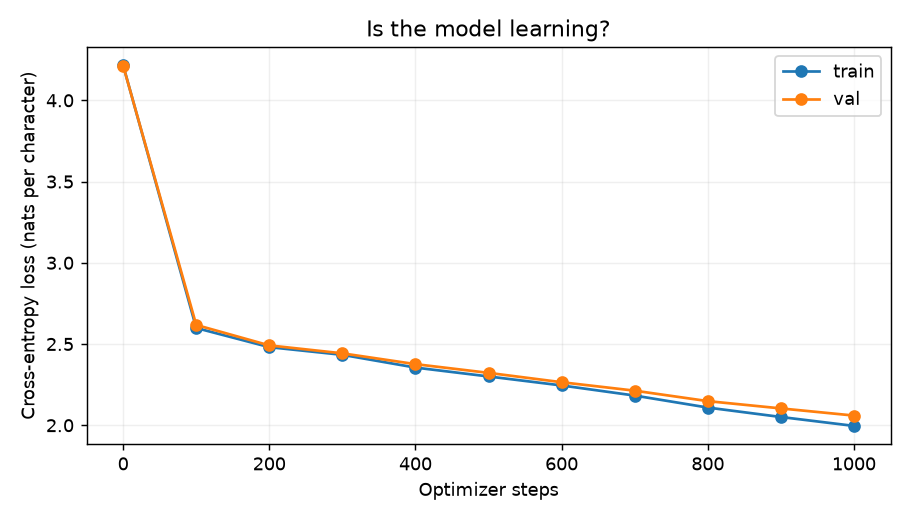

In [11]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 4))
for split in ('train', 'val'):
    plt.plot([r['step'] for r in history], [r[split] for r in history], marker='o', label=split)
plt.xlabel('Optimizer steps')
plt.ylabel('Cross-entropy loss (nats per character)')
plt.title('Is the model learning?')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 5. Reload and experiment with sampling

Generation repeatedly predicts a distribution, samples one character, appends it, and repeats. Only the most recent context window is retained for prediction. Temperature below 1 sharpens the distribution; above 1 makes it more diffuse. `top_k` keeps only the k highest-scoring candidates.

Compare temperatures with the same prompt and random seed. These settings change sampling, not the learned weights. Prompts can contain only characters in the training vocabulary.


In [12]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
loaded, chars = load_model('runs/first/model.pt', device)
stoi = {c: i for i, c in enumerate(chars)}
prompt = 'ROMEO:\n'
seed_ids = torch.tensor([[stoi[c] for c in prompt]], device=device)
for temperature in (0.5, 0.8, 1.2):
    torch.manual_seed(42)
    ids = loaded.generate(seed_ids.clone(), count=250, temperature=temperature, top_k=40)
    print(f'\nTEMPERATURE {temperature}\n' + ''.join(chars[i] for i in ids[0].tolist()))



TEMPERATURE 0.5
ROMEO:
I but wall be you the the me dist noth copters.

FLORES:
I and be lacke stry we spromese,
The must tho and be sice fold cont,
And whast shat ame with hall and we me macht;
The the he seand strue shich see sto with worss thee?


CLOUCEO:
All what we s

TEMPERATURE 0.8
ROMEO:
I, that fat and my my thus mody and on cepreck.

FLORDIIUS:
No, well, will cown sake gon,
The must I of aind dever fold cont,
And whys beht angear thy reas thapt me macht;
The the he in with wull hicess on mar my,
To she mee? wor, me thy leme here to

TEMPERATURE 1.2
ROMEO:
I, t as fate thim segraius mody annd he,
Youckn,
Of I fie, a will lapiwile.

KITHOY RDGREPNANC:
Yow, of nie? Tevy ditle, mang yof's,
For himangsan He url hat grecet mach notHe.


Nodd VTAMOULREO:Ee, anse wilch my, yours veee?
To worest;'elm; hy?

Vir


## Next experiments

Change one thing per run and compare validation loss and samples:

1. Train longer: set `cfg.steps = 3000`, then rerun the training cell. This starts a fresh run.
2. Try a smaller model: halve `cfg.width` while keeping it divisible by `cfg.heads`.
3. Give it more context: double `cfg.context`; attention memory grows approximately quadratically in context length.
4. Try your own UTF-8 text: change the data path, choose a new output folder, and retrain the vocabulary and model together.
5. Remove position embeddings or reduce context and observe what changes.

Our next lesson can implement a bigram baseline and measure whether the transformer actually beats it.

References: [PyTorch cross-entropy](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.cross_entropy.html), [original Transformer paper](https://arxiv.org/abs/1706.03762), [dataset](https://github.com/karpathy/char-rnn/tree/master/data/tinyshakespeare).
